# Apalancamiento y puntos influyentes

> Emiliano Romero Medina


Considerando la base de datos **Prestige** que contiene información sobre diferentes ocupaciones y características socieconómicas, en particular para cada ocupación se tiene la siguiente información:

- **education**: nivel promedio de educación requerido por la ocupación.
- **income**: ingreso promedio asociado a la ocupación.
- **women**: porcentaje de mujeres que desempeñan la ocupación.
- **prestige**: puntuación de prestigio asignada a la ocupación.
- **rownames**: nombre de la ocupación observada.

Así considerando a **prestige** como la variable objetivo y como a **education**, **income** y **women** como variables predictoras se estudiara la presencia de observaciones atípicas, de alto apalancamiento o influyentes.

---

Primero carguemos la base de datos **Prestige**.

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm
import seaborn as sns
import warnings
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, HTML
warnings.filterwarnings('ignore')
pd.set_option('max_colwidth',100)
plt.style.use('ggplot')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = "/content/drive/MyDrive/Modelos Lineales/Tareas/Practica Guiada 2 -  Puntos influyentes con python/prestige.csv"
prest_df = pd.read_csv(path)
prest_df

,rownames,education,income,women,prestige,census,type
0,gov.administrators,13.11,12351,11.16,68.8,1113,prof
1,general.managers,12.26,25879,4.02,69.1,1130,prof
2,accountants,12.77,9271,15.70,63.4,1171,prof
3,purchasing.officers,11.42,8865,9.11,56.8,1175,prof
4,chemists,14.62,8403,11.68,73.5,2111,prof
...,...,...,...,...,...,...,...
93,bus.drivers,7.58,5562,9.47,35.9,9171,bc
94,taxi.drivers,7.93,4224,3.59,25.1,9173,bc
95,longshoremen,8.37,4753,0.00,26.1,9313,bc
96,typesetters,10.00,6462,13.58,42.2,9511,bc


In [ ]:
prest_df.describe()

,education,income,women,prestige,census
count,98.000000,98.000000,98.000000,98.000000,98.000000
mean,10.795102,6938.857143,28.985714,47.327551,5400.061224
std,2.748937,4228.132538,31.382016,17.094907,2684.302381
min,6.380000,1656.000000,0.000000,17.300000,1113.000000
25%,8.445000,4250.500000,3.267500,35.375000,3115.500000
50%,10.605000,6035.500000,14.475000,43.600000,5131.500000
75%,12.755000,8226.250000,52.202500,59.900000,8328.000000
max,15.970000,25879.000000,97.510000,87.200000,9517.000000


Así podemos observar estadísticas desciptivas rápidas de nuestra base de datos, lo que más me llama la atención es la fuerte desviación estándar en la variable **income** que representa los ingresos promedio asociado a la ocupación.

---

Veamos el resultado del siguiente modelo:

$$\text{Prestige}_i=\beta_0+\beta_1*\text{education}_i+\beta_2*\text{income}_i+\beta_3*\text{women}_i$$

In [ ]:
#Variables explicativas
predictors = ["education","income","women"]

#Variable respuesta
target = "prestige"

#Construimos X e Y
X = prest_df[predictors]
Y = prest_df[target]

#Agregamos el intercepto
X = sm.add_constant(X)

#Ajustamos el modelo lineal
prest_model = sm.OLS(Y,X).fit()

#Resumen del modelo
print(prest_model.summary())

                            OLS Regression Results                            
Dep. Variable:               prestige   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     137.5
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           2.99e-34
Time:                        17:22:44   Log-Likelihood:                -334.24
No. Observations:                  98   AIC:                             676.5
Df Residuals:                      94   BIC:                             686.8
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.5242      3.138     -2.398      0.0

Podemos observar que hay una explicación de la varianza de la variable objetivo considerable (0.814), en general el modelo es significativo tras analizar el p-value de la prueba F el cuál es menor al habitual 0.05. Sin embargo, al visualizar la significancia de los coeficientes de manera individual, podemos observar que el perteneciente a la variable **women**, deja de ser significativa, tal vez por la presencia de multicolinealidad que podría verse reflejado en un apalancamiento elevado. El estadístico Durbin-Watson es cercano a 2, por lo que no presenta evidencia de autocorrelación de los residuos, incluso la prueba de Jarque-Bera nos afirma el comportamiento normal de los ya mencionados. Sin embargo, el número de condición parece grande, esto sugiere presencia de multicolinealidad (en la guía el primer parcial hago mención del cálculo deficiente que hace Python de este número de condición, y más considerando que hay variables con escalas muy diferentes, calculemos el mismo número normalizando la matriz diseño).

In [ ]:
def num_cond(modelo):
    """
    Calcula el número de condición de la matriz de diseño
    normalizando cada columna mediante su norma euclidiana.
    """
    # Matriz de diseño
    X = modelo.model.exog #Con el intercepto
    # Norma euclidiana de cada columna
    normas = np.linalg.norm(X, axis=0)
    # Normalización de las columnas
    X_norm = X / normas
    # Valores singulares
    valores_singulares = np.linalg.svd(X_norm, compute_uv=False) #Son las raíces de los eigenvalores de X'X
    # Número de condición
    numero_condicion = (valores_singulares.max() /
        valores_singulares.min())
    return numero_condicion

print(num_cond(prest_model))
print(variance_inflation_factor(X.values, 0))
print(variance_inflation_factor(X.values, 1))
print(variance_inflation_factor(X.values, 2))
print(variance_inflation_factor(X.values, 3))

12.220254268505123
1.0
1.841074265346701
2.2938573033926497
1.5437482944386884


Así como podemos observar el número de condición real es de 12.22, seguido de los VIF menores a 3, así a pesar de la presencia de una leve multicolinealidad, esta no representa una fuerte violación a dicho supuesto.

---

Obtengamos las medidas de diagnóstico asociadas con cada observación, se calcularan el apalancamiento, los residuos studentizados y la distancia de Cook. Existen dos tipos de residuos estudentizados, los internos y externos, los primeros consideran en el cálculo de la varianza global al propio residuo, mientras que los externos lo excluyen para dicho cálculo. Esto se hace dado que si se trata de una observación atípica muy fuerte, la varianza incrementaría mucho, y dado que esta se encuentra como divisor en los residuales studentizados le quitaría fiabilidad a dichos residuales.

In [ ]:
#Objeto con medidas de diagnóstico e influencia
influence = prest_model.get_influence()

#Apalancamiento
prest_df["leverage"] = influence.hat_matrix_diag

#Residuos studentizados internos
prest_df["resid_std"] = influence.resid_studentized_internal

#Distancia de Cook
cooks_distance, _ = influence.cooks_distance
prest_df["cooks_distance"] = cooks_distance

---

Para comparar el comportamiento de los diagnósticos calculados en el punto anterior, es necesario el cálculo de los criterios, los cuales son los siguientes:

- Criterio 2p/n y 3p/n: Dónde p es el número de parámetros del modelo.
- Criterio Cook 4/n: Dónde n es el número de observaciones totales, además valores cercanos o superiores a 1 indican una influencia considerable.

In [ ]:
#Número de observaciones
n = prest_model.nobs

#Número de parámetros estimados, incluyendo el intercepto
p = len(prest_model.params)

#Criterio de apalancamiento
h_mean = p / n
h_2 = 2 * p / n
h_3 = 3 * p / n

#Criterio de Cook
cook_threshold = 4 / n

print(f"Apalancamiento promedio: {h_mean:.4f}")
print(f"Criterio 2p/n: {h_2:.4f}")
print(f"Criterio 3p/n: {h_3:.4f}")
print(f"Criterio Cook 4/n: {cook_threshold:.4f}")

Apalancamiento promedio: 0.0408
Criterio 2p/n: 0.0816
Criterio 3p/n: 0.1224
Criterio Cook 4/n: 0.0408


Ordenamos las observaciones de acuerdo a su apalancamiento.

In [ ]:
prest_df[["rownames", "education", "income", "women",
         "prestige", "leverage"]
         ].sort_values("leverage", ascending=False).head(10)

,rownames,education,income,women,prestige,leverage
1,general.managers,12.26,25879,4.02,69.1,0.356638
23,physicians,15.96,25308,10.56,87.2,0.253981
19,ministers,14.50,4686,4.14,72.8,0.107728
79,sewing.mach.operators,6.38,2847,90.67,28.2,0.102550
16,lawyers,15.77,19263,5.13,82.3,0.101745
25,osteopaths.chiropractors,14.71,17498,6.91,68.4,0.077300
33,secretaries,11.59,4036,97.51,46.0,0.060531
26,nurses,12.46,4614,96.12,64.7,0.060053
43,telephone.operators,10.51,3161,96.14,38.1,0.059006
34,typists,11.49,3148,95.97,41.9,0.057328


Notamos que las observaciones 1, 23, 19, 79, 16 son mayores al primer criterio de apalancamiento $\frac{2p}{n}=0.0816$, mientras que únicamente las observaciones 1 y 23 son mayores al criterio más restrictivo $\frac{3p}{n}=0.1224$, por lo que son observaciones con **alto apalancamiento**.

---

Ahora ordenando las observaciones de acuerdo con la magnitud absoluta de sus residuos studentizados. Se tiene:

In [ ]:
prest_df[["rownames", "education", "income", "women",
          "prestige", "leverage", "resid_std"]
         ].reindex(
             prest_df["resid_std"].abs().sort_values(ascending=False).index
         ).head(10)

,rownames,education,income,women,prestige,leverage,resid_std
44,collectors,11.20,4741,47.06,29.4,0.016318,-2.275196
77,electronic.workers,8.76,3942,74.54,50.8,0.043695,2.248747
28,physio.therapsts,13.62,5092,82.66,72.1,0.050382,2.099694
51,service.station.attendant,9.93,2370,3.69,23.3,0.056465,-2.094925
39,file.clerks,12.09,3016,83.19,32.7,0.045647,-2.048940
30,medical.technicians,12.79,5180,76.04,67.5,0.037908,1.926876
26,nurses,12.46,4614,96.12,64.7,0.060053,1.889207
58,bartenders,8.50,3930,15.51,20.2,0.022950,-1.860922
46,travel.clerks,11.43,6259,39.17,35.7,0.012233,-1.811237
24,veterinarians,15.94,14558,4.32,66.7,0.056723,-1.695801


Así como podemos ver, hay residuales studentizados mayores a 2, que representan residuales atípicos moderadamente, pero ninguno logra superar el umbral más restrictivo de ser mayor a 3. Así las observaciones 44, 77, 28, 51 y 39 son residuales atípicos pero que no habían aparecido como observaciones con fuerte apalancamiento.

---

Estos dos tipos de comportamientos pueden ser estudiados conjuntamente a través de la distancia de Cook.

In [ ]:
prest_df[["rownames", "education", "income", "women",
          "prestige", "leverage", "resid_std", "cooks_distance"]
         ].sort_values("cooks_distance", ascending=False).head(10)

,rownames,education,income,women,prestige,leverage,resid_std,cooks_distance
1,general.managers,12.26,25879,4.02,69.1,0.356638,-1.190452,0.196397
19,ministers,14.50,4686,4.14,72.8,0.107728,1.645488,0.081726
51,service.station.attendant,9.93,2370,3.69,23.3,0.056465,-2.094925,0.065659
28,physio.therapsts,13.62,5092,82.66,72.1,0.050382,2.099694,0.058476
77,electronic.workers,8.76,3942,74.54,50.8,0.043695,2.248747,0.057764
26,nurses,12.46,4614,96.12,64.7,0.060053,1.889207,0.057008
39,file.clerks,12.09,3016,83.19,32.7,0.045647,-2.048940,0.050200
24,veterinarians,15.94,14558,4.32,66.7,0.056723,-1.695801,0.043232
23,physicians,15.96,25308,10.56,87.2,0.253981,-0.685688,0.040017
30,medical.technicians,12.79,5180,76.04,67.5,0.037908,1.926876,0.036573


Podemos observar que todas las observaciones con mayor Distancia de Cook ya habían sido identificadas con Alto Apalancamiento o con Residuales Studentizados elevados, no es una sorpresa debido a que en la distancia de Cook interfieren a la vez ambas estadísticas por observación. Para ver si hay observaciones con Distancia de Cook elevadas, se muestra la siguiente gráfica:

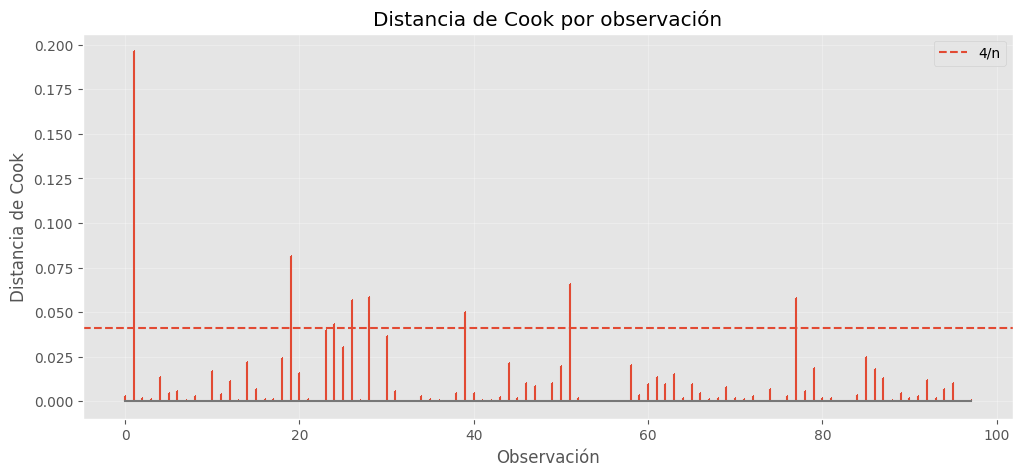

In [ ]:
plt.figure(figsize=(12,5))

plt.stem(
    prest_df.index,
    prest_df['cooks_distance'],
    markerfmt=","
)

plt.axhline(
    cook_threshold,
    linestyle="--",
    label=r"4/n"
)

plt.xlabel("Observación")
plt.ylabel("Distancia de Cook")
plt.title("Distancia de Cook por observación")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

Podemos ver que las observaciones 1, 19, 51, 28, 77, 26, 39 y 24 son las que presentan una distancia de Cook superior al criterio $\frac{4}{n}=0.0408$, notemos que la observación 1 es la que tienen una muy fuerte influencia en el modelo, las 3 ocupaciones con distancia de Cook más elevadas son:

- general.managers
- ministers
- service.station.attendant

---

Veamos un modelo dónde se eliminarán temporalmente las siguientes ocupaciones:
- general.managers
- physicians
- collectors
Para evaluar la influencia del modelo cuando estás observaciones se omiten.

In [ ]:
# Profesiones a analizar
profesiones = ["general.managers",
               "physicians",
               "collectors"]

# DataFrame para almacenar los coeficientes de cada modelo
comparacion_modelos = pd.DataFrame({
    "Modelo original": prest_model.params
})

# Ajustamos un modelo eliminando temporalmente cada profesion
for profesion in profesiones:
    # Filtramos el DataFrame para excluir la profesion actual
    prest_temp = prest_df[prest_df["rownames"] != profesion].copy()

    #Variables explicativas
    X_temp = prest_temp[predictors]

    #Variable respuesta
    Y_temp = prest_temp[target]

    #Agregamos el intercepto
    X_temp = sm.add_constant(X_temp)

    #Ajustamos el modelo lineal
    prest_temp_model = sm.OLS(Y_temp,X_temp, missing="drop").fit()

    #Agregamos los coeficientes al DataFrame de comparacion
    comparacion_modelos[f"Sin {profesion}"] = prest_temp_model.params

comparacion_modelos


,Modelo original,Sin general.managers,Sin physicians,Sin collectors
const,-7.524222,-7.305152,-7.769639,-7.557810
education,4.362425,4.169092,4.314971,4.399019
income,0.001172,0.001407,0.001269,0.001141
women,-0.012946,-0.000669,-0.007973,-0.011805


Veamos que la mayoría no presenta cambios tan fuertes a nivel error absoluto, sin embargo, debemos de considerar las magnitudes o escalas de los coeficientes, para ello se calcula el cambio relativo producido en cada coeficiente.

In [ ]:
#Calculamos el cambio de los coeficientes respecto al modelo original
for profesion in profesiones:
    comparacion_modelos[f"Cambio sin {profesion}"] = (
        comparacion_modelos[f"Sin {profesion}"]
        - comparacion_modelos["Modelo original"]
    )/comparacion_modelos["Modelo original"]

comparacion_modelos

,Modelo original,Sin general.managers,Sin physicians,Sin collectors,Cambio sin general.managers,Cambio sin physicians,Cambio sin collectors
const,-7.524222,-7.305152,-7.769639,-7.557810,-0.029115,0.032617,0.004464
education,4.362425,4.169092,4.314971,4.399019,-0.044318,-0.010878,0.008389
income,0.001172,0.001407,0.001269,0.001141,0.199825,0.082879,-0.026973
women,-0.012946,-0.000669,-0.007973,-0.011805,-0.948348,-0.384100,-0.088171


Los cambios relativos más grandes se presentan cuando la observación más influyente es eliminada, de manera general el coeficiente asociado a la variable **women** es el que presenta mayor variabilidad cuando una observación influyente es omitida.

In [ ]:
def comparar_sensibilidad(profesion):

  #Eliminamos temporalmente la profesión seleccionada
  prest_temp = prest_df[prest_df["rownames"] != profesion].copy()

  #Construimos el nuevo modelo
  X_temp = prest_temp[predictors]
  Y_temp = prest_temp[target]
  X_temp = sm.add_constant(X_temp)

  modelo_temp = sm.OLS(Y_temp,X_temp, missing="drop").fit()

  #Calculamos el cambio de los coeficientes respecto al modelo original
  comparacion = pd.DataFrame({
      "Modelo original": prest_model.params,
      f"Sin {profesion}": modelo_temp.params})

  comparacion["Cambio"] = (
      comparacion[f"Sin {profesion}"]
      - comparacion["Modelo original"]
  )/comparacion["Modelo original"]

  return comparacion

In [ ]:
comparar_sensibilidad("general.managers")

,Modelo original,Sin general.managers,Cambio
const,-7.524222,-7.305152,-0.029115
education,4.362425,4.169092,-0.044318
income,0.001172,0.001407,0.199825
women,-0.012946,-0.000669,-0.948348


In [ ]:
comparar_sensibilidad("physicians")

,Modelo original,Sin physicians,Cambio
const,-7.524222,-7.769639,0.032617
education,4.362425,4.314971,-0.010878
income,0.001172,0.001269,0.082879
women,-0.012946,-0.007973,-0.384100


In [ ]:
comparar_sensibilidad("collectors")

,Modelo original,Sin collectors,Cambio
const,-7.524222,-7.557810,0.004464
education,4.362425,4.399019,0.008389
income,0.001172,0.001141,-0.026973
women,-0.012946,-0.011805,-0.088171


---
### Preguntas de análisis

- **Apalancamiento**: De acuerdo con los criterios 2p/n y 3p/n, ¿qué observaciones pueden considerarse de alto apalancamiento? Identifique las ocupaciones correspondientes y explique qué características de sus variables explicativas podrían justificar estos valores elevados de $h_{ii}$.

Para evaluar el apalancamiento de las observaciones se consideró un apalancamiento promedio de 0.0408, estableciendo como criterios de referencia 2p/n=0.0816 y 3p/n=0.1224.

De acuerdo con el criterio 2p/n, se identificaron cinco observaciones con apalancamiento elevado: **general.managers** $h_{ii}$=0.356638, **physicians** $h_{ii}$=0.253981, **ministers** $h_{ii}$=0.107728, **sewing.mach.operators** $h_{ii}$=0.102550 y **lawyers** $h_{ii}$=0.101745.

Al utilizar el criterio más estricto de 3p/n=0.1224, únicamente dos observaciones superan el umbral: general.managers y physicians. Estas presentan valores de 0.356638 y 0.253981, respectivamente, por lo que destacan considerablemente.

En particular, general.managers presenta el mayor apalancamiento de toda la muestra, seguido por physicians. Esto indica que ambas observaciones presentan una combinación de valores de las variables explicativas considerablemente alejada del centro de la matriz de diseño, en particular en variables como **income** y **prestige**, es decir, tienen un ingreso promedio superior a las de las demás y además un prestigio elevado, sobre todo la ocupación de **physicians**.

---

- **Residuos Studentizados**: ¿Qué observaciones presentan los residuos studentizados de mayor magnitud? ¿Coinciden estas observaciones con aquellas que presentan mayor apalancamiento? Explique por qué ambos diagnósticos pueden identificar observaciones diferentes.

En este caso, las observaciones que presentan los residuos studentizados de mayor magnitud son **collectors** -2.2752, **electronic.workers** 2.2487, **physio.therapsts** 2.0997, **service.station.attendant** -2.0949 y **file.clerks** -2.0489. Por lo tanto, considerando como referencia $|r_i|>2$, estas cinco observaciones pueden considerarse casos que requieren especial atención.

Estas observaciones no coinciden con aquellas que presentan mayor apalancamiento. Las observaciones con mayor leverage fueron general.managers, physicians, ministers, sewing.mach.operators y lawyers, mientras que sus residuos no se encuentran entre los de mayor magnitud. Esto se debe a que ambos diagnósticos evalúan aspectos diferentes del ajuste.

El apalancamiento mide qué tan alejada se encuentra una observación respecto al centro de las variables explicativas (X). Por su parte, el residuo studentizado mide qué tan alejado se encuentra el valor observado de la variable respuesta respecto a la predicción realizada por el modelo.

---

- **Distancia de Cook**: Utilizando 4/n como criterio exploratorio identifique las observaciones que presentan las mayores distancias de Cook. ¿La observación con mayor distancia de Cook es también la que presenta el residuo studentizado de mayor magnitud? ¿Qué explica este resultado?

La distancia de Cook permite evaluar de manera conjunta el efecto que tiene una observación sobre el ajuste global del modelo, considerando tanto el tamaño de su residuo como su posición dentro del espacio de las variables explicativas. Utilizando como criterio exploratorio 4/n=0.0408, se identifican las observaciones cuya distancia de Cook supera este valor.

Las observaciones que exceden el criterio son: **general.managers** D_i=0.1964, **ministers** D_i=0.0817, **service.station.attendant** D_i=0.0657, **physio.therapsts** D_i=0.0585, **electronic.workers** D_i=0.0578, **nurses** D_i=0.0570, **file.clerks** D_i=0.0502 y **veterinarians** D_i=0.0432. Estas observaciones presentan un nivel de influencia que, bajo este criterio exploratorio, justifica una revisión adicional.

Destaca particularmente la observación **general.managers**, que presenta la mayor distancia de Cook de toda la muestra, con D_i=0.1964. Sin embargo, no es la observación que presenta el residuo studentizado de mayor magnitud. Su residuo studentizado es -1.1905, mientras que el mayor valor absoluto corresponde a **collectors**, con $|r_i|=2.2752$.

Este resultado se explica porque la distancia de Cook no depende exclusivamente del tamaño del residuo. En términos generales, está determinada por la combinación del residuo y el apalancamiento de la observación. De forma esquemática,

$$
D_i \propto
\frac{r_i^2}{p}
\frac{h_{ii}}{1-h_{ii}}
$$

Por lo tanto, una observación puede tener una distancia de Cook elevada aunque su residuo no sea el más grande, siempre que presente un apalancamiento suficientemente elevado.

Esto ocurre claramente con **general.managers**: aunque su residuo studentizado es relativamente moderado -1.1905, presenta un leverage extraordinariamente alto de 0.3566. En consecuencia, esta observación tiene una capacidad considerable para modificar las estimaciones del modelo y termina presentando la mayor distancia de Cook.

---

- **general.managers**. Analice conjuntamente el apalancamiento, residuo studentizado y distancia de Cook de general.managers. Posteriormente, compare los coeficientes del modelo original con los obtenidos al retirar temporalmente esta observación. ¿Existe evidencia de que sea una observación influyente? Justifique.

En primer lugar, su apalancamiento es de 0.356638, valor considerablemente superior al criterio 3p/n=0.1224. De hecho, es la observación con mayor leverage de la muestra, lo que indica que se encuentra en una posición extremadamente alejada del centro de las variables explicativas.

Por otro lado, su residuo studentizado es -1.190452, por lo que no presenta un residuo particularmente grande en términos de magnitud. Esto indica que, aunque el modelo presenta cierto error de predicción para esta observación, general.managers no destaca principalmente por ser atípica en la variable respuesta.

Sin embargo, su distancia de Cook es 0.196397, valor considerablemente superior al criterio exploratorio 4/n=0.0408. Además, es la mayor distancia de Cook entre las observaciones analizadas. La combinación de un leverage extremadamente elevado con un residuo de magnitud moderada explica que esta observación tenga una influencia considerable sobre el ajuste global del modelo.

La posible influencia de general.managers se evalúa adicionalmente comparando los coeficientes del modelo original con los obtenidos al retirar temporalmente dicha observación:

Los cambios más importantes se observan en los coeficientes asociados con **income** y **women**. El coeficiente de income pasa de 0.001172 a 0.001407, lo que representa un cambio relativo aproximado del 19.98%. Este cambio, aunque relevante, es considerablemente menor que el observado en women.

El caso más notable corresponde a women, cuyo coeficiente pasa de -0.012946 a -0.000669. Esto representa un cambio relativo de aproximadamente -94.83% en la magnitud reportada y, más importante aún desde el punto de vista de la interpretación, implica que el efecto estimado de esta variable se aproxima considerablemente a cero al retirar la observación.

En contraste, los coeficientes de la constante y education presentan cambios relativamente pequeños, de aproximadamente 2.91% y 4.43%, respectivamente. Por lo tanto, el efecto de general.managers no es uniforme sobre todos los parámetros del modelo: su influencia se concentra principalmente en determinados coeficientes.

---

- **physicians**. La ocupación **physicians** presenta uno de los valores de apalancamiento más elevados del conjunto de datos. ¿Su distancia de Cook y el análisis de sensibilidad indican también una influencia particularmente elevada? ¿Qué permite concluir este caso acerca de la relación entre alto apalancamiento e influencia?

La observación physicians presenta un apalancamiento de 0.253981, el segundo valor más elevado de la muestra y considerablemente superior al criterio 3p/n=0.1224. Por lo tanto, se encuentra en una posición particularmente alejada del centro de las variables explicativas y, desde el punto de vista del leverage, constituye una observación potencialmente problemática.

Sin embargo, su residuo studentizado es de -0.685688, cuya magnitud es relativamente pequeña. Esto indica que, aunque physicians presenta valores poco comunes en las variables explicativas, su valor observado de la variable respuesta no se encuentra particularmente alejado de lo que predice el modelo.

Esta situación también se refleja en su distancia de Cook, que es de 0.040017. Este valor se encuentra ligeramente por debajo del criterio exploratorio 4/n=0.0408. Por lo tanto, de acuerdo con este criterio, physicians no se identifica como una observación particularmente influyente, a pesar de su elevado apalancamiento.

El análisis de sensibilidad confirma esta conclusión. Al retirar temporalmente physicians, los coeficientes del modelo presentan los siguientes cambios:

El coeficiente de education prácticamente permanece estable, con una variación de aproximadamente 1.09%, mientras que el coeficiente de income presenta un cambio de 8.29%. El mayor cambio corresponde a women, cuyo coeficiente pasa de -0.012946 a -0.007973, representando una variación relativa aproximada de 38.41%. Aunque este cambio merece atención, no alcanza la magnitud observada para general.managers, donde el coeficiente de women se modificaba aproximadamente un 94.83%.

En conjunto, no existe evidencia suficiente para considerar a physicians una observación particularmente influyente. A pesar de presentar un leverage excepcionalmente elevado 0.253981, su residuo studentizado es pequeño -0.685688, su distancia de Cook se encuentra ligeramente por debajo del criterio establecido y la eliminación de la observación produce cambios relativamente moderados en los coeficientes.

---

- **collectors**. Compare el residuo studentizado, el apalancamiento y la distancia de Cook de collectors. Posteriormente, examine los cambios producidos en los coeficientes al retirarla temporalmente. ¿Qué permite concluir este caso acerca de la relación entre una observación atípica e influencia?

La observación **collectors** presenta el residuo studentizado de mayor magnitud entre las observaciones analizadas, con un valor de -2.275196. Esto indica que su valor observado de la variable respuesta se encuentra considerablemente alejado del valor predicho por el modelo y, tomando como referencia $|r_i|>2$, puede considerarse una observación atípica en términos de la variable respuesta.

Sin embargo, su apalancamiento es de apenas 0.016318, valor considerablemente inferior al apalancamiento promedio de 0.0408. Por lo tanto, collectors no ocupa una posición extrema dentro del espacio de las variables explicativas. En otras palabras, la observación destaca por su discrepancia en la variable respuesta, pero no porque sus valores de las variables explicativas sean particularmente inusuales.

Esta combinación se refleja directamente en su distancia de Cook, que es de 0.021468. Dicho valor se encuentra por debajo del criterio exploratorio 4/n=0.0408, por lo que no existe evidencia, bajo este diagnóstico, de que collectors tenga una influencia importante sobre el ajuste global del modelo.

Los cambios en los coeficientes son relativamente pequeños. La constante y education prácticamente no se modifican, con variaciones inferiores al 1%. El coeficiente de income cambia aproximadamente un 2.70%, mientras que el mayor cambio corresponde a women, con una variación aproximada del 8.82%. Estos cambios son considerablemente menores que los observados al retirar general.managers, particularmente en el coeficiente de women.

Este caso permite concluir que una observación atípica no necesariamente es una observación influyente. El hecho de que collectors presente un residuo studentizado elevado significa que constituye una observación inusual respecto a la variable respuesta, pero su posición dentro del espacio de las variables explicativas es común. Por ello, su eliminación tiene poco efecto sobre las estimaciones del modelo.

---

- **Conclusión general**. A partir de los resultados obtenidos para general.managers, physicians y collectors, explique por qué los conceptos de observación atípica, alto apalancamiento y observación influyente no son equivalentes. ¿Considera que alguna de estas observaciones debería eliminarse automáticamente del conjunto de datos? Justifique su respuesta.

En primer lugar, una observación **atípica** se identifica principalmente a partir de un residuo de gran magnitud, es decir, cuando el valor observado de la variable respuesta se encuentra considerablemente alejado del valor que predice el modelo. El caso de collectors constituye un ejemplo claro: presenta el mayor residuo studentizado en magnitud, con un valor de -2.275196, por lo que puede considerarse una observación atípica respecto a la variable respuesta. Sin embargo, su apalancamiento es bajo 0.016318 y su distancia de Cook es de apenas 0.021468, por debajo del criterio 4/n=0.0408. Además, al eliminarla temporalmente, los cambios en los coeficientes son pequeños. Por lo tanto, ser atípica no implica necesariamente ser influyente.

Por otro lado, el alto **apalancamiento** se refiere a una observación que ocupa una posición poco común dentro del espacio de las variables explicativas. Physicians presenta un leverage de 0.253981, el segundo más elevado de la muestra y muy superior al criterio 3p/n=0.1224. No obstante, su residuo studentizado es relativamente pequeño -0.685688 y su distancia de Cook 0.040017 se encuentra ligeramente por debajo del criterio establecido. En consecuencia, aunque physicians presenta un apalancamiento excepcionalmente elevado, no existe evidencia suficiente para considerarla una observación particularmente influyente. Este caso demuestra que un alto leverage tampoco implica automáticamente una alta influencia.

Finalmente, general.managers representa el caso en el que ambas características se combinan de manera importante. Su apalancamiento es de 0.356638, el mayor de la muestra y considerablemente superior al criterio 3p/n=0.1224. Aunque su residuo studentizado es moderado -1.190452, su **distancia de Cook** alcanza 0.196397, muy por encima del criterio 4/n=0.0408. Además, al retirar temporalmente esta observación se producen cambios importantes en algunos coeficientes, particularmente en income y women. Por lo tanto, general.managers sí constituye una observación influyente, aun cuando no sea una observación atípica en términos de su residuo.

Por lo anterior, ninguna de las tres observaciones debería eliminarse automáticamente del conjunto de datos. Superar un criterio diagnóstico constituye una señal para realizar una investigación adicional, pero no es, por sí mismo, una justificación para eliminar una observación. Antes de excluirla debe verificarse si existe un error de captura, medición o registro. Si los datos son correctos y la observación representa una característica real de la población estudiada, eliminarla únicamente porque afecta al modelo podría introducir un sesgo y hacer que las conclusiones sean menos representativas.

En particular, collectors no debería eliminarse simplemente por presentar el residuo studentizado de mayor magnitud, ya que su influencia sobre el modelo es reducida. Physicians tampoco debería eliminarse únicamente por su elevado leverage, debido a que su distancia de Cook y el análisis de sensibilidad no muestran una influencia sustancial. En el caso de general.managers, existe una razón más fuerte para investigar la observación debido a su leverage excepcional y a su elevada distancia de Cook; sin embargo, incluso en este caso la eliminación no debe realizarse automáticamente. Si sus valores son válidos, lo apropiado sería conservarla y reconocer que el modelo es sensible a esta observación, complementando el análisis con una evaluación de sensibilidad.